# Vier Grafiken zur Bundesliga-Datensichtung

Beschreibung beobachteter Ergebnisse, keine Modellschätzung. Hauptzeitraum: 1995/96–2010/11 (4.896 Spiele). Die Zusatzsaison 1994/95 wird ausgeschlossen. Quelle: footballcsv/deutschland, gesicherter Stand im Rohdatenmanifest. Alle Tordifferenzen sind unbereinigt. Ausführliche Herkunft: `results/Datensichtung_Bundesliga.md`.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/processed/footballcsv/matches.csv").exists())
assert Path(sys.executable).resolve() == (ROOT / ".venv/Scripts/python.exe").resolve()
all_matches = pd.read_csv(ROOT / "data/processed/footballcsv/matches.csv")
matches = all_matches.loc[all_matches.season.between("1995/96", "2010/11")].copy()
assert len(matches) == 4896 and matches.match_id.is_unique
assert matches.groupby("season").size().eq(306).all()
OUT = ROOT / "results/figures/deskriptiv"
OUT.mkdir(parents=True, exist_ok=True)
TABLES = ROOT / "results/tables/deskriptiv"
TABLES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
BLUE, ORANGE, GRAY = "#2463A0", "#D47732", "#8794A3"

def finish(fig, filename, note):
    fig.text(0.01, 0.015, note + " | Quelle: footballcsv/deutschland", fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, .055, 1, 1))
    fig.savefig(OUT / (filename + ".png"), dpi=180, bbox_inches="tight")
    fig.savefig(OUT / (filename + ".svg"), bbox_inches="tight")
    plt.show()


## 1. Durchschnittliche Tore pro Spiel je Saison
Gesamttore sowie Heim- und Gasttore werden jeweils durch die Zahl der Spiele geteilt. Die Linien beschreiben das Torniveau; sie sind keine angepassten Trendmodelle.

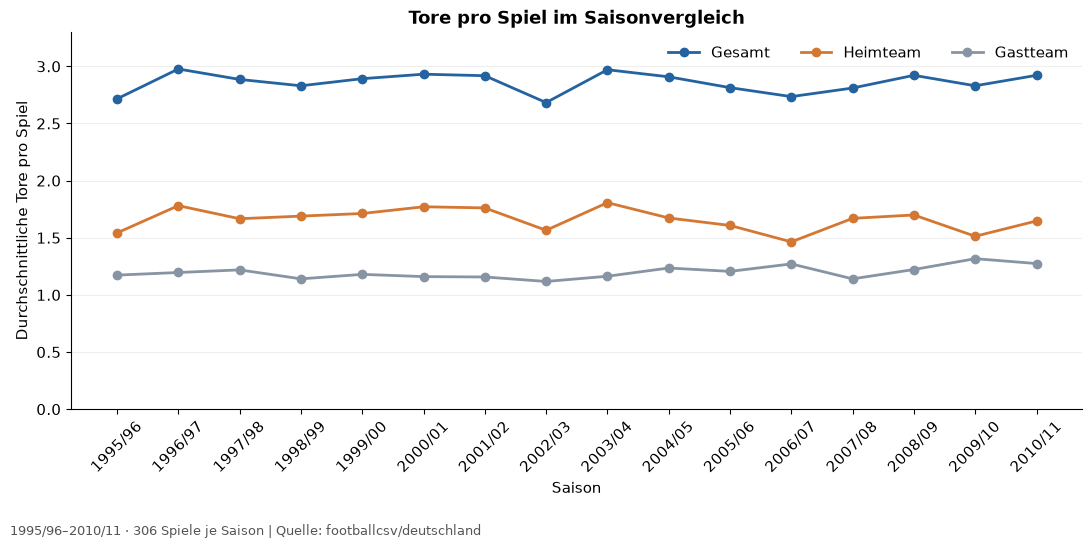

In [2]:
goals = matches.groupby("season")[["total_goals", "home_goals", "away_goals"]].mean()
goals.to_csv(TABLES / "01_tore_pro_spiel.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 5.5))
for col, label, color in [("total_goals", "Gesamt", BLUE), ("home_goals", "Heimteam", ORANGE), ("away_goals", "Gastteam", GRAY)]:
    ax.plot(goals.index, goals[col], marker="o", label=label, color=color, linewidth=2)
ax.set(title="Tore pro Spiel im Saisonvergleich", ylabel="Durchschnittliche Tore pro Spiel", xlabel="Saison", ylim=(0, 3.3))
ax.tick_params(axis="x", rotation=45)
ax.legend(ncol=3, frameon=False)
ax.grid(axis="y", alpha=.2)
finish(fig, "01_tore_pro_spiel", "1995/96–2010/11 · 306 Spiele je Saison")


## 2. Heimsiege, Unentschieden und Auswärtssiege
Jeder Balken umfasst alle Spiele einer Saison. Die drei Anteile summieren sich auf 100 Prozent.

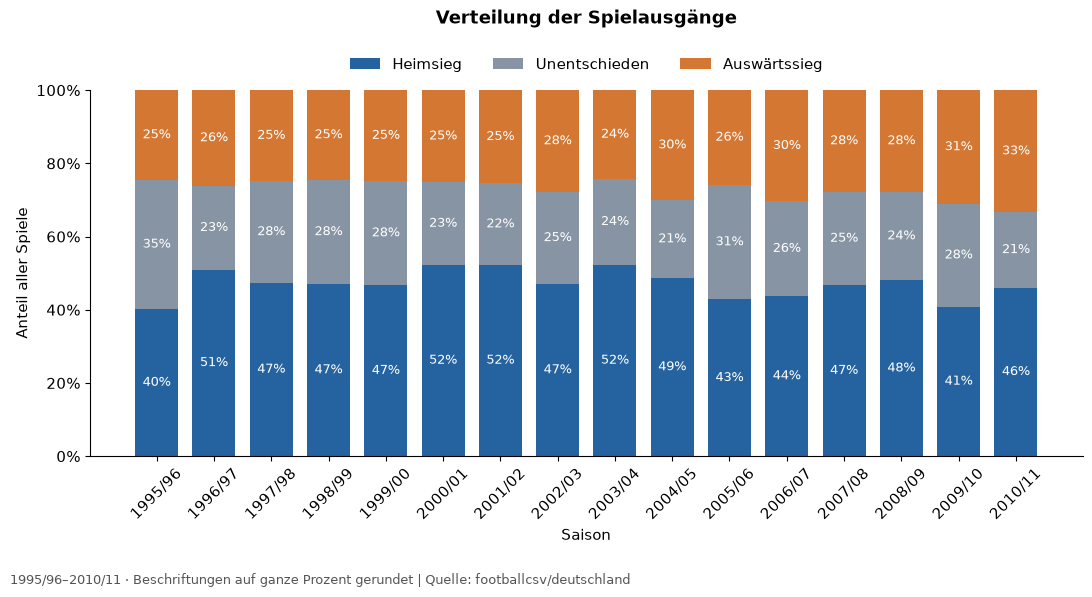

In [3]:
counts = pd.crosstab(matches.season, matches.result).reindex(columns=["H", "D", "A"], fill_value=0)
shares = counts.div(counts.sum(axis=1), axis=0)
assert np.allclose(shares.sum(axis=1), 1)
shares.to_csv(TABLES / "02_ergebnisanteile.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 6))
bottom = np.zeros(len(shares))
for key, label, color in [("H", "Heimsieg", BLUE), ("D", "Unentschieden", GRAY), ("A", "Auswärtssieg", ORANGE)]:
    values = shares[key].to_numpy()
    ax.bar(shares.index, values, bottom=bottom, label=label, color=color, width=.75)
    for i, value in enumerate(values):
        ax.text(i, bottom[i] + value / 2, f"{value:.0%}", ha="center", va="center", color="white", fontsize=9)
    bottom += values
ax.set(title="Verteilung der Spielausgänge", ylabel="Anteil aller Spiele", xlabel="Saison", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="lower center", bbox_to_anchor=(.5, 1.01), ncol=3, frameon=False)
ax.set_title("Verteilung der Spielausgänge", pad=48)
finish(fig, "02_spielausgaenge", "1995/96–2010/11 · Beschriftungen auf ganze Prozent gerundet")


## 3. Tordifferenzen aus Sicht der Heimmannschaft
Negative Werte bedeuten Auswärtssiege, null bedeutet Remis, positive Werte Heimsiege. Alle beobachteten Tordifferenzen sind enthalten, ohne Abschneiden seltener Ergebnisse.

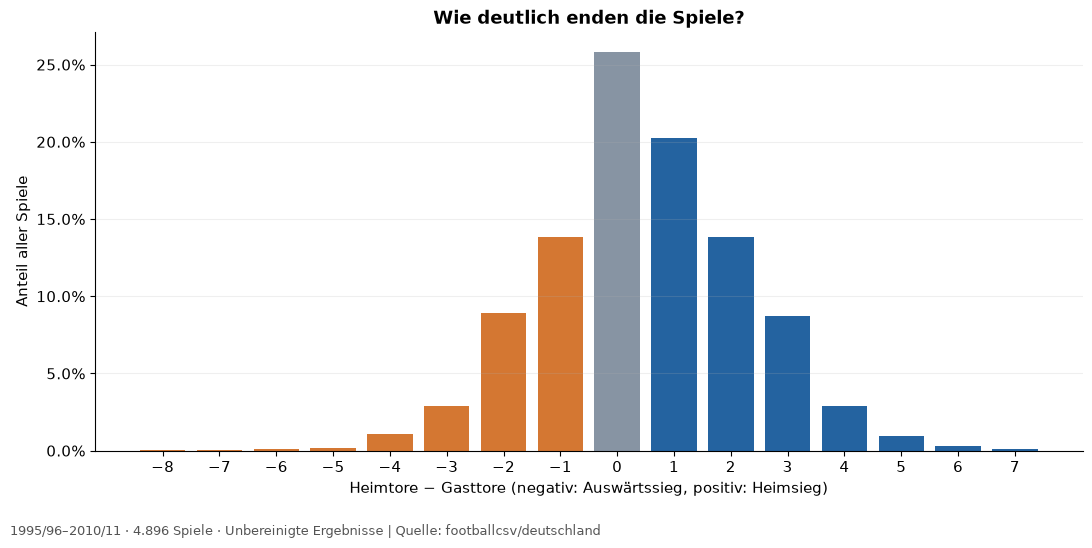

In [4]:
diff = matches.goal_difference_home
freq = diff.value_counts().reindex(range(int(diff.min()), int(diff.max()) + 1), fill_value=0).sort_index()
assert freq.sum() == len(matches)
distribution = pd.DataFrame({"matches": freq, "share": freq / len(matches)})
distribution.index.name = "goal_difference_home"
distribution.to_csv(TABLES / "03_tordifferenzen.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 5.5))
colors = [ORANGE if d < 0 else GRAY if d == 0 else BLUE for d in freq.index]
ax.bar(freq.index, freq / len(matches), color=colors, width=.8)
ax.set(title="Wie deutlich enden die Spiele?", xlabel="Heimtore − Gasttore (negativ: Auswärtssieg, positiv: Heimsieg)", ylabel="Anteil aller Spiele")
ax.set_xticks(freq.index)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", alpha=.2)
finish(fig, "03_tordifferenzen", "1995/96–2010/11 · 4.896 Spiele · Unbereinigte Ergebnisse")


## 4. Hin- und Rückrundenbilanz je Mannschaft 2007/08
Die Balken zeigen die Summe der Tordifferenzen über jeweils 17 Spiele. Teams sind nach der gesamten Saisontordifferenz sortiert. Eine Veränderung der beobachteten Bilanz ist kein isolierter Nachweis einer veränderten wahren Stärke.

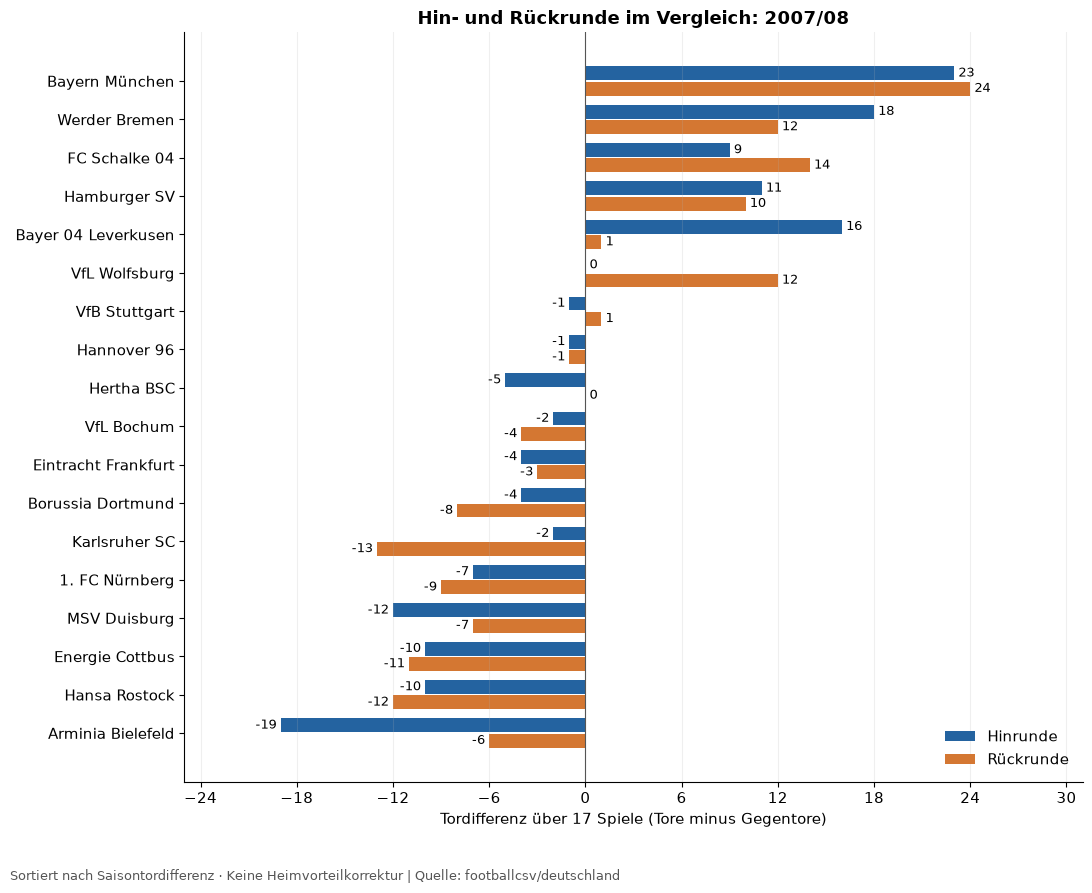

In [5]:
halves = pd.read_csv(ROOT / "data/processed/footballcsv/team_halves.csv")
h = halves.loc[halves.season.eq("2007/08")]
assert len(h) == 36 and h.matches.eq(17).all()
balance = h.pivot(index="team", columns="half", values="goal_difference")
balance["Gesamt"] = balance["Hinrunde"] + balance["Rückrunde"]
balance = balance.sort_values("Gesamt", ascending=False)
assert balance[["Hinrunde", "Rückrunde"]].sum().eq(0).all()
balance.to_csv(TABLES / "04_halbserien_2007_08.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 9))
y = np.arange(len(balance))
for offset, half, color in [(-.2, "Hinrunde", BLUE), (.2, "Rückrunde", ORANGE)]:
    bars = ax.barh(y + offset, balance[half], height=.36, label=half, color=color)
    ax.bar_label(bars, padding=3, fontsize=9)
ax.set_yticks(y, balance.index)
ax.invert_yaxis()
ax.axvline(0, color="#555555", linewidth=.8)
ax.set(title="Hin- und Rückrunde im Vergleich: 2007/08", xlabel="Tordifferenz über 17 Spiele (Tore minus Gegentore)")
ax.set_xlim(min(balance.Hinrunde.min(), balance.Rückrunde.min()) - 6, max(balance.Hinrunde.max(), balance.Rückrunde.max()) + 7)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", alpha=.2)
ax.legend(loc="lower right", frameon=False)
finish(fig, "04_halbserien_2007_08", "Sortiert nach Saisontordifferenz · Keine Heimvorteilkorrektur")
